# Unidad III · Regresión y clasificación
Ulises González Coronado · Recursamiento ECBD 2026

Dataset Energy Efficiency de UCI. Ejecutar de arriba hacia abajo con el entorno del repositorio.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/preparacion_datos.py').exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
print('Proyecto:', ROOT.name)


Proyecto: REC_ECBD_2026_Gonzalez_Ulises


## 1. X, y y separación
X = X1-X8; regresión = Y1/Y2. Clasificación: alta si Y1 ≥ 25, baja en otro caso. Regla didáctica fijada antes de entrenar. Se excluyen identificadores, objetivos y clase de las entradas. La fecha sintética ordena un corte 70/30: 537 filas de entrenamiento y 231 de prueba futura simulada.

In [2]:
df = pd.read_csv(ROOT / 'data/processed/eficiencia_energetica_procesada.csv')
display(df.head())
from src.modelos_supervisados import ajustar_modelos
resultado = ajustar_modelos()
display(resultado)

,id_registro,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2,fecha_simulada,grupo_geometria,clase_calefaccion
0,1,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33,2025-01-01,12,baja
1,2,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33,2025-01-02,12,baja
2,3,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33,2025-01-03,12,baja
3,4,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33,2025-01-04,12,baja
4,5,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28,2025-01-05,11,baja


Separación temporal 70/30: 537 entrenamiento / 231 prueba.
Regresión seleccionada mediante validación: Ridge {'modelo__alpha': 10.0}
          modelo objetivo    MAE    RMSE      R2
           Ridge       Y1 2.2025  2.9852  0.9186
           Ridge       Y2 2.3316  3.2475  0.8905
Referencia_media       Y1 9.7010 11.1841 -0.1426
Referencia_media       Y2 9.0216 10.2140 -0.0834
Clasificación seleccionada mediante validación: Logistica {'modelo__C': 0.1}
            modelo  accuracy  precision_macro  recall_macro  F1_macro
         Logistica    1.0000           1.0000           1.0    1.0000
Referencia_mayoria    0.5195           0.2597           0.5    0.3419
Matriz de confusión [baja, alta]: [[120, 0], [0, 111]]


{'semilla': 42,
 'entrenamiento_filas': 537,
 'prueba_filas': 231,
 'estrategia_particion': 'Corte cronológico 70/30 con fecha simulada; prueba representa horizonte futuro simulado',
 'geometrias_entrenamiento': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12],
 'geometrias_prueba': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12],
 'geometrias_compartidas': 12,
 'validacion': 'GroupKFold de 3 particiones solo en entrenamiento',
 'regresion': {'modelo': 'Ridge',
  'parametros': {'modelo__alpha': 10.0},
  'MAE_cv': 3.9177439424372142},
 'clasificacion': {'modelo': 'Logistica',
  'parametros': {'modelo__C': 0.1},
  'F1_macro_cv': 0.846567245825927,
  'umbral_Y1': 25.0,
  'matriz_confusion_baja_alta': [[120, 0], [0, 111]]},
 'versiones': {'python': '3.13.2',
  'sklearn': '1.8.0',
  'pandas': '2.3.3',
  'numpy': '2.5.4',
  'joblib': '1.6.0'},
 'limite': 'La fecha es sintética y solo permite demostrar un flujo temporal. No prueba desempeño futuro ni causalidad en edificios reales.'}

## 2. Comparación y mejora
Pipeline ajusta escalamiento y OneHotEncoder dentro de cada fold. GridSearchCV compara Ridge/Random Forest y logística/Random Forest con GroupKFold de tres particiones. Se ajustan alpha, profundidad, hojas mínimas y C, según el algoritmo. El criterio de selección usa únicamente entrenamiento.

In [3]:
display(pd.read_csv(ROOT/'docs/validacion_regresion.csv'))
display(pd.read_csv(ROOT/'docs/validacion_clasificacion.csv'))

,modelo,parametros,metrica_cv,desviacion_cv
0,Ridge,"{""modelo__alpha"": 0.1}",4.750968,1.104614
1,Ridge,"{""modelo__alpha"": 1.0}",4.526978,1.153763
2,Ridge,"{""modelo__alpha"": 10.0}",3.917744,1.069983
3,RandomForest,"{""modelo__max_depth"": 8, ""modelo__min_samples_...",5.261746,1.203863
4,RandomForest,"{""modelo__max_depth"": 8, ""modelo__min_samples_...",5.277552,1.232950
5,RandomForest,"{""modelo__max_depth"": null, ""modelo__min_sampl...",5.272785,1.245082
6,RandomForest,"{""modelo__max_depth"": null, ""modelo__min_sampl...",5.295609,1.220730


,modelo,parametros,metrica_cv,desviacion_cv
0,Logistica,"{""modelo__C"": 0.1}",0.846567,0.105139
1,Logistica,"{""modelo__C"": 1.0}",0.820251,0.074417
2,Logistica,"{""modelo__C"": 10.0}",0.812340,0.070841
3,RandomForest,"{""modelo__max_depth"": 6, ""modelo__min_samples_...",0.776585,0.042418
4,RandomForest,"{""modelo__max_depth"": 6, ""modelo__min_samples_...",0.776585,0.042418
5,RandomForest,"{""modelo__max_depth"": null, ""modelo__min_sampl...",0.774138,0.051641
6,RandomForest,"{""modelo__max_depth"": null, ""modelo__min_sampl...",0.776585,0.042418


## 3. Regresión
MAE mide error absoluto en la escala original; RMSE penaliza errores grandes; R² compara contra la variación de la prueba. Los errores no son porcentajes. La referencia de la media se ajusta en entrenamiento.

,modelo,objetivo,MAE,RMSE,R2
0,Ridge,Y1,2.202544,2.985243,0.918598
1,Ridge,Y2,2.331634,3.247533,0.890474
2,Referencia_media,Y1,9.700999,11.184091,-0.142551
3,Referencia_media,Y2,9.021631,10.214028,-0.083438


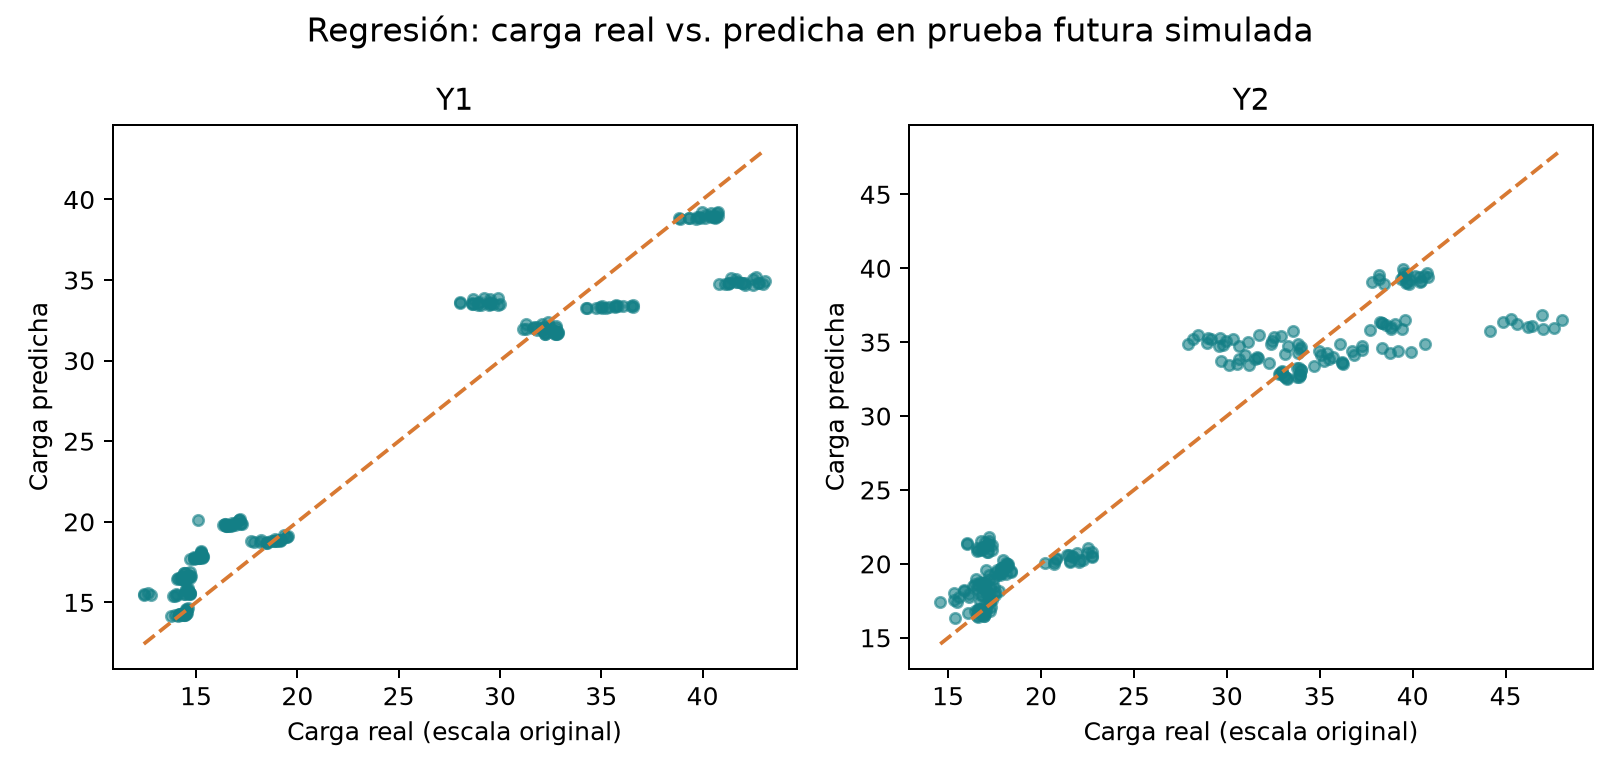

In [4]:
display(pd.read_csv(ROOT/'docs/metricas_regresion.csv'))
display(Image(filename=str(ROOT/'docs/figuras/04_regresion_prueba.png')))

## 4. Clasificación
Accuracy = proporción de aciertos. Precision/Recall/F1 se informan por clase y en promedio macro. La logística reconoce las 120 cargas bajas y las 111 altas de esta prueba futura simulada. El 100% no debe extrapolarse: la fecha fue creada para demostrar el flujo temporal y no reemplaza validación con datos reales.

,modelo,accuracy,precision_macro,recall_macro,F1_macro
0,Logistica,1.000000,1.00000,1.0,1.00000
1,Referencia_mayoria,0.519481,0.25974,0.5,0.34188


,precision,recall,f1-score,support
baja,1.0,1.0,1.0,120.0
alta,1.0,1.0,1.0,111.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,231.0
weighted avg,1.0,1.0,1.0,231.0


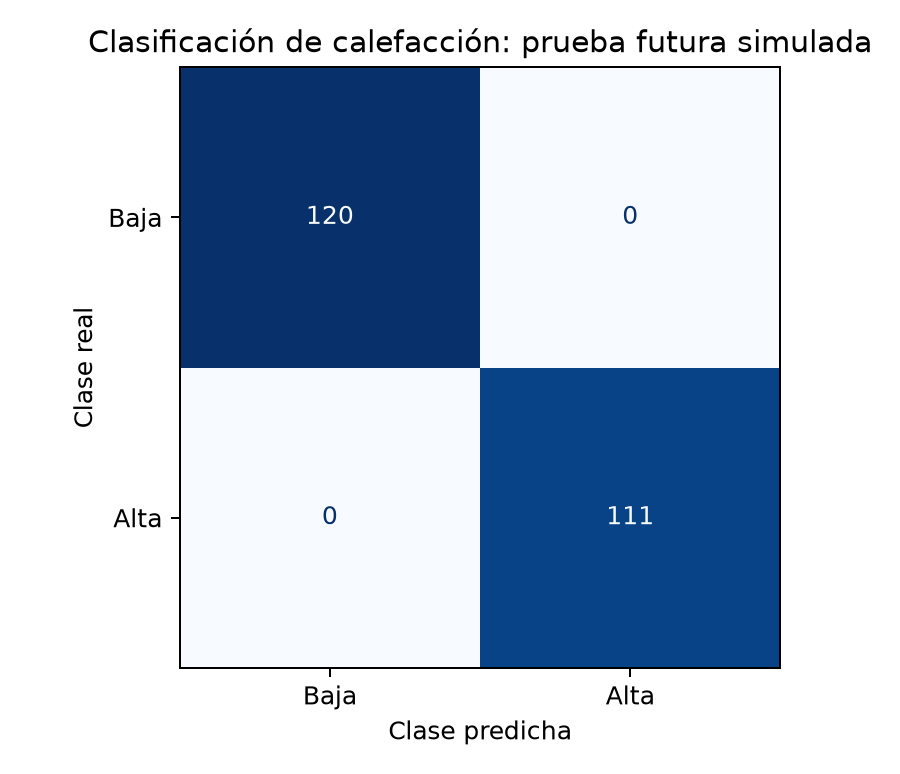

In [5]:
display(pd.read_csv(ROOT/'docs/metricas_clasificacion.csv'))
display(pd.DataFrame(json.loads((ROOT/'docs/reporte_clasificacion.json').read_text(encoding='utf-8'))).T)
display(Image(filename=str(ROOT/'docs/figuras/03_matriz_confusion.png')))

## 5. Relevancia y límites
La importancia por permutación se calcula después de seleccionar los modelos, sin reentrenar con la prueba. La correlación entre variables geométricas limita su interpretación individual. Una división de solo 12 geometrías simuladas no demuestra desempeño en edificios reales.

In [6]:
imp = pd.read_csv(ROOT/'docs/importancia_variables.csv')
display(imp.sort_values(['tarea','importancia_media'], ascending=[True,False]))

,tarea,variable,importancia_media,desviacion
12,clasificacion,X5,0.296464,0.028222
11,clasificacion,X4,0.104850,0.017804
10,clasificacion,X3,0.043295,0.008877
9,clasificacion,X2,0.033769,0.010022
8,clasificacion,X1,0.000000,0.000000
13,clasificacion,X6,0.000000,0.000000
14,clasificacion,X7,0.000000,0.000000
15,clasificacion,X8,0.000000,0.000000
4,regresion,X5,6.754801,0.541786
3,regresion,X4,1.471293,0.129870


## 6. Utilidad
La regresión apoya la comparación de cargas estimadas. La clasificación resume una regla didáctica y no sustituye mediciones reales. Las diferencias de altura y compacidad están confundidas: no se presenta causalidad.